<a href="https://colab.research.google.com/github/gilchristes/CapstoneProject-group8/blob/main/tdr_inversion_capstone.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# S3 EC Capstone Project | Problem B: Transmission-Line Signal Integrity
## Recovering the Hidden $R(x)$ and $C(x)$ Profiles of a Cable from its TDR Echo
### Department of Electronics and Communication Engineering | APJ Abdul Kalam Technological University (KTU)

---

**Group 8 Members:**
* Gilchrist (Roll No. 32)
* Gokul (Roll No. 33)
* G Sibiraj (Roll No. 34)
* Thejus (Roll No. 67)
* Aydin (Roll No. 18)

---

### Abstract & Overview
A transmission line (coaxial cable or PCB trace) of length $\ell = 1.0\text{ m}$ has per-unit-length distributed parameters resistance $R(x)$ and capacitance $C(x)$ that deviate from nominal due to an internal fault near $x \approx 0.5\text{ m}$. In practical non-destructive testing, the only accessible port is the input at $x = 0$, where an input voltage step is applied and the reflected signal—the **Time-Domain Reflectometry (TDR)** trace—is recorded.

This project presents an end-to-end mathematical and numerical inversion framework:
1. **Field Model & Governing PDE Formulation**: Starting from Maxwell's curl equations, Stokes' theorem yields the coupled first-order Telegrapher's system, which reduces to a second-order hyperbolic damped wave PDE.
2. **Transform-Domain Analysis**: Laplace transformation yields the complex propagation coefficient $\gamma(s)$, characteristic impedance $Z_0(s)$, and reflection coefficient $\Gamma(s)$, proving why $R(x)$ deviations produce minimal echo compared to $C(x)$.
3. **FDTD Discretization & Sensitivity Linearization**: Leapfrog staggered-grid discretization simulates the forward line dynamics, and numerical perturbation constructs the Jacobian sensitivity matrix $\mathbf{A}$.
4. **Sparse $\ell_1$ Linear Programming Inversion**: Formulated as a constrained $\ell_1$ minimization problem via epigraph slacks and solved with the HiGHS solver, successive linear programming (SLP) reconstructs the spatial fault profile.

## 1. Mathematical Formulation: Telegrapher's System to the Governing Wave PDE

### 1.1 Field Derivation to Telegrapher's Equations
Consider a two-conductor transmission line slice of infinitesimal length $\Delta x$ with per-unit-length distributed parameters $R$ $(\Omega/\text{m})$, $L$ $(\text{H}/\text{m})$, $G$ $(\text{S}/\text{m})$, and $C$ $(\text{F}/\text{m})$. Applying Faraday's law of induction and Ampère-Maxwell's law via Stokes' theorem on an elemental loop yields the first-order coupled Telegrapher's system:

$$\frac{\partial V(x,t)}{\partial x} = -R I(x,t) - L \frac{\partial I(x,t)}{\partial t}$$

$$\frac{\partial I(x,t)}{\partial x} = -G V(x,t) - C \frac{\partial V(x,t)}{\partial t}$$

### 1.2 Second-Order Governing PDE Derivation
To obtain a decoupled partial differential equation in terms of voltage $V(x,t)$:

1. Differentiate the voltage equation with respect to space $x$:
   $$\frac{\partial^2 V}{\partial x^2} = -R \frac{\partial I}{\partial x} - L \frac{\partial^2 I}{\partial x \partial t}$$

2. Differentiate the current equation with respect to time $t$:
   $$\frac{\partial^2 I}{\partial t \partial x} = -G \frac{\partial V}{\partial t} - C \frac{\partial^2 V}{\partial t^2}$$

3. Assuming spatial and temporal smoothness (Clairaut's theorem: $\frac{\partial^2 I}{\partial x \partial t} = \frac{\partial^2 I}{\partial t \partial x}$), substitute $\frac{\partial I}{\partial x}$ and $\frac{\partial^2 I}{\partial x \partial t}$ into the spatial derivative:
   $$\frac{\partial^2 V}{\partial x^2} = -R\left(-G V - C \frac{\partial V}{\partial t}\right) - L\left(-G \frac{\partial V}{\partial t} - C \frac{\partial^2 V}{\partial t^2}\right)$$

4. Rearranging terms yields the second-order **damped wave (Telegrapher) PDE**:
   $$\frac{\partial^2 V(x,t)}{\partial x^2} = L C \frac{\partial^2 V(x,t)}{\partial t^2} + (R C + L G) \frac{\partial V(x,t)}{\partial t} + R G V(x,t)$$

Similarly, for current $I(x,t)$:
$$\frac{\partial^2 I(x,t)}{\partial x^2} = L C \frac{\partial^2 I(x,t)}{\partial t^2} + (R C + L G) \frac{\partial I(x,t)}{\partial t} + R G I(x,t)$$

### 1.3 PDE Classification and Propagation Characteristics
Writing the general linear second-order PDE in coordinates $(x, t)$:
$$A \frac{\partial^2 V}{\partial x^2} + B \frac{\partial^2 V}{\partial x \partial t} + C_{pde} \frac{\partial^2 V}{\partial t^2} + D \frac{\partial V}{\partial x} + E \frac{\partial V}{\partial t} + F V = 0$$

Here, $A = 1$, $B = 0$, and $C_{pde} = -LC$. The discriminant evaluates to:
$$\Delta = B^2 - 4 A C_{pde} = 0 - 4(1)(-LC) = 4LC > 0$$

Because $L > 0$ and $C > 0$, the discriminant $\Delta > 0$ strictly holds everywhere. The PDE is therefore **strictly hyperbolic**.
* **Finite Wave Speed**: Discontinuities and wavefronts travel along characteristics $\frac{dx}{dt} = \pm \frac{1}{\sqrt{LC}}$ at phase velocity $v = \frac{1}{\sqrt{LC}} = 2 \times 10^8\text{ m/s}$.
* **Damping**: The first-order derivative terms $(RC + LG)$ enforce energy dissipation along the line.

### 1.4 Boundary and Initial Conditions
* **Source Boundary ($x = 0$)**: An active voltage step $V_s(t)$ with source resistance $R_s = Z_0 = 50\,\Omega$:
  $$V(0,t) = V_s(t) - R_s I(0,t)$$
* **Load Boundary ($x = \ell = 1.0\text{ m}$)**: Matched resistive load $R_L = Z_0 = 50\,\Omega$:
  $$V(\ell, t) = R_L I(\ell, t)$$
* **Initial Conditions**: Quiescent line at $t \le 0$:
  $$V(x,0) = 0, \quad \frac{\partial V(x,0)}{\partial t} = 0, \quad I(x,0) = 0$$

## 2. Laplace Analysis, FDTD Discretization & $\ell_1$ Linear Programming

### 2.1 Laplace Transform Domain Analysis
Taking the unilateral Laplace transform in $t$ with zero initial state transforms the coupled system into ordinary spatial differential equations:
$$\frac{d\hat{V}(x,s)}{dx} = -(R + Ls) \hat{I}(x,s)$$
$$\frac{d\hat{I}(x,s)}{dx} = -(G + Cs) \hat{V}(x,s)$$

The complex propagation constant $\gamma(s)$ and characteristic impedance $Z_0(s)$ are defined as:
$$\gamma(s) = \sqrt{(R + Ls)(G + Cs)}, \qquad Z_0(s) = \sqrt{\frac{R + Ls}{G + Cs}}$$

At a local impedance transition from $Z_1$ to $Z_2$, the voltage reflection coefficient is:
$$\Gamma = \frac{Z_2 - Z_1}{Z_2 + Z_1}$$

For small series losses ($R \ll \omega L$, $G = 0$):
$$\gamma(s) \approx s\sqrt{LC} + \alpha, \quad \text{where } \alpha \approx \frac{R}{2 Z_0}$$
Because $R_0 = 0.1\,\Omega/\text{m}$, $\alpha \approx 0.001\text{ Np/m}$, producing an attenuation of only $\approx 0.1\%$ over the entire line length. A four-fold resistance fault over 3 grid cells adds a series resistance of only $\Delta R_{tot} \approx 0.018\,\Omega$, yielding a reflection magnitude of only $0.09\text{ mV}$ (well within the baseline noise floor). Conversely, a $40\%$ decrease in capacitance shifts $Z_0$ significantly from $50\,\Omega$ to $64.5\,\Omega$, producing an observable echo of $\approx 70\text{ mV}$.

---

### 2.2 Semi-Implicit Staggered-Grid FDTD Scheme
Using spatial grid index $i$ ($x_i = i\Delta x$) and temporal index $n$ ($t^n = n\Delta t$), current nodes $I_{i+1/2}^{n+1/2}$ are staggered at half-space cells between voltage nodes $V_i^n$:

$$I_{i+1/2}^{n+1/2} = \frac{\left(\frac{L_{i+1/2}}{\Delta t} - \frac{R_{i+1/2}}{2}\right) I_{i+1/2}^{n-1/2} - \frac{V_{i+1}^n - V_i^n}{\Delta x}}{\frac{L_{i+1/2}}{\Delta t} + \frac{R_{i+1/2}}{2}}$$

$$V_i^{n+1} = V_i^n - \frac{\Delta t}{C_i \Delta x} \left( I_{i+1/2}^{n+1/2} - I_{i-1/2}^{n+1/2} \right) - \frac{\Delta t G_i}{C_i} V_i^n$$

Numerical stability is bounded by the Courant-Friedrichs-Lewy (CFL) condition:
$$\Delta t \le \frac{\Delta x}{v_{\max}} = \Delta x \sqrt{L_0 C_{\min}}$$
For $\Delta x = 20.4\text{ mm}$, $\Delta t = 75\text{ ps}$, the effective CFL number is $\text{CFL} \approx 0.949 < 1.0$.

---

### 2.3 $\ell_1$ Linear Programming and Successive Linearization (SLP)
Let baseline perturbation parameter $\mathbf{p} = [\mathbf{p}_R; \mathbf{p}_C] \in \mathbb{R}^{2N_x}$ parameterize relative changes:
$$R_j = R_0 (1 + p_{R,j}), \qquad C_j = C_0 (1 - p_{C,j}), \quad p_{R,j} \ge 0, \; 0 \le p_{C,j} < 1$$

The deviation vector $\mathbf{b} = V_{\text{meas}} - V_{\text{nom}}$ is linearly approximated as $\mathbf{b} \approx \mathbf{A} \mathbf{p}$, with Jacobian columns evaluated through central/forward difference perturbations. To remain resilient against measurement outliers, the $\ell_1$-norm misfit with epigraph slacks $\varepsilon_k$ is minimized:

$$\min_{\mathbf{p}, \boldsymbol{\varepsilon}} \sum_{k=1}^{N_t} \varepsilon_k + \lambda \sum_{j=1}^{2N_x} p_j$$
$$\text{subject to} \quad -\varepsilon_k \le (\mathbf{A}\mathbf{p} - \mathbf{b})_k \le \varepsilon_k, \quad \mathbf{p} \ge \mathbf{0}, \quad \boldsymbol{\varepsilon} \ge \mathbf{0}$$

Successive Linear Programming (SLP) iteratively updates $\mathbf{p}^{(k+1)} = \mathbf{p}^{(k)} + \Delta \mathbf{p}$ over four passes, re-evaluating the local sensitivity matrix $\mathbf{A}(\mathbf{p}^{(k)})$ to eliminate first-order linearization drift.

<>:349: SyntaxWarning: invalid escape sequence '\D'
<>:366: SyntaxWarning: invalid escape sequence '\O'
<>:349: SyntaxWarning: invalid escape sequence '\D'
<>:366: SyntaxWarning: invalid escape sequence '\O'
/tmp/ipykernel_3982/1944957709.py:349: SyntaxWarning: invalid escape sequence '\D'
  ax1[1].set_ylabel("$\Delta V$ (mV)")
/tmp/ipykernel_3982/1944957709.py:366: SyntaxWarning: invalid escape sequence '\O'
  ax2[1].set_ylabel("$R(x)$ ($\Omega$/m)")


=== QUANTITATIVE RUN RESULTS ===
{
 "open_plateau_before": 0.5002921938988996,
 "open_plateau_after": 1.0001436548642528,
 "open_echo_time_ns": 10.274999999999999,
 "delay_expected_ns": 10.0,
 "match_plateau": 0.5002345973959842,
 "Z0": 50.0,
 "v": 200000000.0,
 "cfl": 0.9488809198208172,
 "dt_ps": 75.0,
 "NT": 128,
 "dx_mm": 20.408163265306122,
 "peak_dev_C_only_mV": 69.5348761586696,
 "peak_dev_R_only_mV": 0.093946700809866,
 "peak_dev_both_mV": 69.57558043231205,
 "dR_total_ohm": 0.018367346938775512,
 "t_fault_ns": 4.8979591836734695,
 "lp_status_single": 0,
 "lp_success_single": true,
 "resid_l1_hist": [
  0.3142536181227784,
  0.08520660041319837,
  0.012302833082107095,
  0.007804349003101934
 ],
 "lp_status_slp": [
  0,
  0,
  0,
  0
 ],
 "A_shape": [
  128,
  100
 ],
 "lp_vars": 228,
 "lp_cons": 256,
 "single": {
  "argmaxC": 25,
  "centroidC": 24.724953365577505,
  "maxC": 0.5634476315845631,
  "sumC": 1.2241225784381287,
  "maxR": 0.0,
  "neg_param": false
 },
 "slp": {
  "a

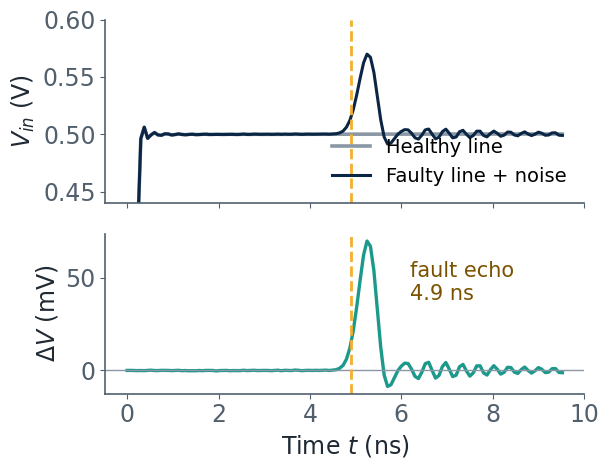

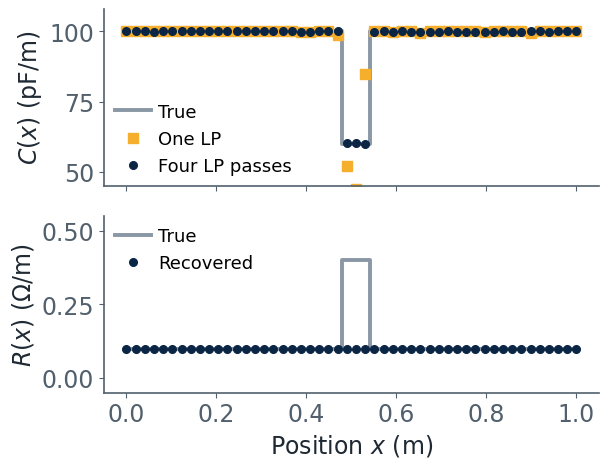

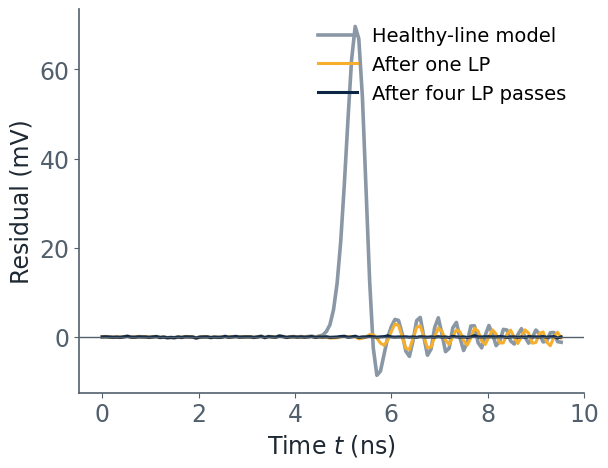

Execution complete. Output figures saved successfully.


In [ ]:
# =====================================================================
# Transmission-Line Signal Integrity: TDR Inversion by l1 Linear Programming
# Group 8 Capstone (PDEs, Transforms & Optimization Techniques)
# Stack: Python 3 with NumPy, SciPy (HiGHS linprog solver), and Matplotlib
# Outputs: results.json, data.npz, fig_tdr.png, fig_recon.png, fig_resid.png
# =====================================================================

import json
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import font_manager as fm
from scipy.optimize import linprog
from scipy.sparse import hstack, identity, csr_matrix

# ---------------------------------------------------------------------
# PART 1: PHYSICAL CONSTANTS & FDTD FORWARD SIMULATOR
# ---------------------------------------------------------------------
ELL = 1.0             # Cable length (m)
NX = 50               # Number of spatial nodes
DX = ELL / (NX - 1)   # Spatial grid step: dx = 20.408 mm
R0, L0, G0, C0 = 0.1, 250e-9, 0.0, 100e-12
Z0 = np.sqrt(L0 / C0) # Matched characteristic impedance: 50.0 Ohm
RS = Z0               # Source internal resistance (matched)
VS = 1.0              # Input step amplitude (V)
TR = 0.4e-9           # Rise time (s)
DT = 0.075e-9         # Time step: dt = 75 ps (CFL = 0.949)
TMAX = 9.6e-9         # Acquisition recording window (s)
NT = int(round(TMAX / DT)) # 128 time samples
T = np.arange(NT) * DT
FAULT = [24, 25, 26]  # Internal spatial fault location (x ~ 0.49 to 0.53 m)


def step(t):
    """Raised-cosine voltage step excitation."""
    u = np.clip(t / TR, 0.0, 1.0)
    return VS * 0.5 * (1.0 - np.cos(np.pi * u))


def tdr(R, C, RL=None, nt=NT, L=None, G=None):
    """Semi-implicit staggered leapfrog FDTD solver for Telegrapher's PDE.
    Returns input voltage trace V[0, t] over nt time steps."""
    RL = Z0 if RL is None else RL
    L = np.full(NX, L0) if L is None else L
    G = np.zeros(NX) if G is None else G

    Rh = 0.5 * (R[:-1] + R[1:])
    Lh = 0.5 * (L[:-1] + L[1:])
    V = np.zeros(NX)
    I = np.zeros(NX - 1)

    Cn = C.copy()
    Cn[0] *= 0.5
    Cn[-1] *= 0.5
    out = np.empty(nt)

    a = Lh / DT - Rh / 2.0
    b = Lh / DT + Rh / 2.0

    for n in range(nt):
        t_half = (n + 0.5) * DT
        # Current update (staggered half-cells)
        I = (a * I - (V[1:] - V[:-1]) / DX) / b

        # Interior Voltage update
        Vn = V.copy()
        Vn[1:-1] = V[1:-1] + DT / Cn[1:-1] * (-(I[1:] - I[:-1]) / DX - G[1:-1] * V[1:-1])

        # Source boundary condition (node 0)
        k0 = DT / (Cn[0] * DX)
        Vn[0] = (V[0] + k0 * (step(t_half) / RS - I[0])) / (1.0 + k0 / RS)

        # Load boundary condition (node NX-1)
        kL = DT / (Cn[-1] * DX)
        Vn[-1] = (V[-1] + kL * I[-1]) / (1.0 + kL / RL)

        V = Vn
        out[n] = V[0]
    return out


def true_profiles():
    """Generates true ground-truth R(x) and C(x) spatial profiles."""
    R = np.full(NX, R0)
    C = np.full(NX, C0)
    R[FAULT] *= 4.0   # 4x resistance spike
    C[FAULT] *= 0.6   # 40% capacitance drop (60 pF/m)
    return R, C


# ---------------------------------------------------------------------
# PART 2: SENSITIVITY MATRIX & LINEAR PROGRAM SOLVERS
# ---------------------------------------------------------------------
def jacobian(h_r=0.5, h_c=0.05):
    """Assembles sensitivity Jacobian matrix A about the healthy line."""
    Rn = np.full(NX, R0)
    Cn = np.full(NX, C0)
    v0 = tdr(Rn, Cn)
    A = np.zeros((NT, 2 * NX))
    for j in range(NX):
        R = Rn.copy()
        R[j] *= (1.0 + h_r)
        A[:, j] = (tdr(R, Cn) - v0) / h_r

        C = Cn.copy()
        C[j] *= (1.0 - h_c)
        A[:, NX + j] = (tdr(Rn, C) - v0) / h_c
    return v0, A


def solve_l1(A, b, lam=0.0, ub=(10.0, 0.95)):
    """Standard single-pass l1 Linear Program using HiGHS solver:
    min sum(eps) + lam*sum(p)  s.t. -eps <= A p - b <= eps,  p >= 0"""
    m, n = A.shape
    c = np.concatenate([lam * np.ones(n), np.ones(m)])
    As = csr_matrix(A)
    I = identity(m, format="csr")
    A_ub = np.vstack([
        hstack([As, -I]).toarray(),
        hstack([-As, -I]).toarray(),
    ])
    b_ub = np.concatenate([b, -b])
    bounds = [(0, ub[0])] * (n // 2) + [(0, ub[1])] * (n // 2) + [(0, None)] * m
    res = linprog(c, A_ub=A_ub, b_ub=b_ub, bounds=bounds, method="highs")
    return res


# ---------------------------------------------------------------------
# SUCCESSIVE LINEAR PROGRAMMING (SLP) MULTI-PASS SOLVER
# ---------------------------------------------------------------------
def model(p, r0=R0, **kw):
    R = r0 * (1.0 + p[:NX])
    C = C0 * (1.0 - p[NX:])
    return tdr(R, C, **kw)


def jac_at(p, r0=R0, dR=0.5, dC=0.02):
    v = model(p, r0)
    A = np.zeros((NT, 2 * NX))
    for j in range(NX):
        q = p.copy()
        q[j] += dR
        A[:, j] = (model(q, r0) - v) / dR
        q = p.copy()
        q[NX + j] += dC
        A[:, NX + j] = (model(q, r0) - v) / dC
    return v, A


def lp_step(A, r, p, lam=0.0, trR=2.0, trC=0.3, ub=(10.0, 0.95)):
    m, n = A.shape
    c = np.concatenate([lam * np.ones(n), np.ones(m)])
    I = identity(m, format="csr")
    As = csr_matrix(A)
    A_ub = np.vstack([hstack([As, -I]).toarray(), hstack([-As, -I]).toarray()])
    b_ub = np.concatenate([r, -r])
    hi = np.concatenate([np.minimum(ub[0] - p[:NX], trR), np.minimum(ub[1] - p[NX:], trC)])
    bounds = [(-p[i], hi[i]) for i in range(n)] + [(0, None)] * m
    res = linprog(c, A_ub=A_ub, b_ub=b_ub, bounds=bounds, method="highs")
    return res


def invert(b, r0=R0, iters=4, lam=0.0, verbose=False):
    p = np.zeros(2 * NX)
    hist = []
    for k in range(iters):
        v, A = jac_at(p, r0)
        r = b - v
        res = lp_step(A, r, p, lam=lam)
        assert res.success, res.message
        p = np.clip(p + res.x[:2 * NX], 0, None)
        hist.append((np.abs(b - model(p, r0)).sum(), res.status))
        if verbose:
            print(f"Pass {k}: Residual L1 = {hist[-1][0]:.6f}, Status = {hist[-1][1]}")
    return p, hist


# ---------------------------------------------------------------------
# PART 3: EXPERIMENTAL PROTOCOLS & NOISE STUDY
# ---------------------------------------------------------------------
SIG = 0.1e-3  # 0.1 mV Gaussian measurement noise
rng = np.random.default_rng(7)
Rt, Ct = true_profiles()
Rn = np.full(NX, R0)
Cn = np.full(NX, C0)

v0 = tdr(Rn, Cn)
vf = tdr(Rt, Ct)
b = vf + rng.normal(0, SIG, NT)
out = {}

# Open-ended verification
nt = int(16e-9 / DT)
vo = tdr(Rn, Cn, RL=1e9, nt=nt)
to = np.arange(nt) * DT
mm = to > 5e-9
cross = to[mm][np.argmax(vo[mm] > 0.75)]

out["open_plateau_before"] = float(vo[(to > 3e-9) & (to < 9e-9)].mean())
out["open_plateau_after"] = float(vo[(to > 12.5e-9) & (to < 15e-9)].mean())
out["open_echo_time_ns"] = float(cross * 1e9)
out["delay_expected_ns"] = float(2 * ELL * np.sqrt(L0 * C0) * 1e9)
out["match_plateau"] = float(v0[30:100].mean())
out["Z0"] = float(Z0)
out["v"] = float(1.0 / np.sqrt(L0 * C0))
out["cfl"] = float(np.sqrt(1.0 / (L0 * C0 * 0.6)) * DT / DX)
out["dt_ps"] = DT * 1e12
out["NT"] = NT
out["dx_mm"] = DX * 1e3

# Relative sensitivity analysis of R vs C faults
Ro = Rn.copy()
Ro[FAULT] *= 4.0
Co = Cn.copy()
Co[FAULT] *= 0.6

out["peak_dev_C_only_mV"] = float(np.abs(tdr(Rn, Co) - v0).max() * 1e3)
out["peak_dev_R_only_mV"] = float(np.abs(tdr(Ro, Cn) - v0).max() * 1e3)
out["peak_dev_both_mV"] = float(np.abs(vf - v0).max() * 1e3)
out["dR_total_ohm"] = float((4.0 - 1.0) * R0 * 3 * DX)
t_fault = 2 * FAULT[0] * DX * np.sqrt(L0 * C0) * 1e9
out["t_fault_ns"] = float(t_fault)

# LP Inversion Runs
lam = 0.02
_, A0 = jacobian()
res1 = solve_l1(A0, b - v0, lam=lam)
p1 = res1.x[:2 * NX]
p, hist = invert(b, iters=4, lam=lam)

out["lp_status_single"] = int(res1.status)
out["lp_success_single"] = bool(res1.success)
out["resid_l1_hist"] = [float(h[0]) for h in hist]
out["lp_status_slp"] = [int(h[1]) for h in hist]
out["A_shape"] = list(A0.shape)
out["lp_vars"] = int(2 * NX + NT)
out["lp_cons"] = int(2 * NT)


def centroid(pc):
    w = np.where(pc > 0.1 * pc.max(), pc, 0)
    return float((w * np.arange(NX)).sum() / w.sum())


for name, pp in [("single", p1), ("slp", p)]:
    pC = pp[NX:]
    out[name] = {
        "argmaxC": int(pC.argmax()),
        "centroidC": centroid(pC),
        "maxC": float(pC.max()),
        "sumC": float(pC.sum()),
        "maxR": float(pp[:NX].max()),
        "neg_param": bool((pp < -1e-9).any()),
    }

out["true"] = {"centroid": 25.0, "maxC": 0.4, "sumC": 1.2}

Rrec = R0 * (1.0 + p[:NX])
Crec = C0 * (1.0 - p[NX:])
R1 = R0 * (1.0 + p1[:NX])
C1 = C0 * (1.0 - p1[NX:])

out["min_R_rec"] = float(Rrec.min())
out["min_C_rec_pF"] = float(Crec.min() * 1e12)
out["C_rec_at_fault_pF"] = [float(Crec[i] * 1e12) for i in FAULT]
out["rmse_C_pF"] = float(np.sqrt(np.mean((Crec - Ct) ** 2)) * 1e12)

# Residual series
res_nom = (b - v0) * 1e3
res_single = (b - (v0 + A0 @ p1)) * 1e3
res_slp = (b - model(p)) * 1e3
out["resid_rms_mV"] = {
    "nominal": float(np.sqrt(np.mean(res_nom ** 2))),
    "single": float(np.sqrt(np.mean(res_single ** 2))),
    "slp": float(np.sqrt(np.mean(res_slp ** 2))),
}

# Multi-seed noise study
sweep = {}
for sg in [0.1, 0.5, 1.0, 2.0]:
    errs = []
    amps = []
    for s in range(10):
        r_noise = np.random.default_rng(100 + s)
        bb = vf + r_noise.normal(0, sg * 1e-3, NT)
        pp, _ = invert(bb, iters=4, lam=lam)
        errs.append(centroid(pp[NX:]) - 25.0)
        amps.append(pp[NX:].max())
    sweep[str(sg)] = {
        "mean_abs_err": float(np.mean(np.abs(errs))),
        "max_abs_err": float(np.max(np.abs(errs))),
        "mean_amp": float(np.mean(amps)),
        "std_amp": float(np.std(amps)),
    }
out["sweep"] = sweep

# Save outputs
with open("results.json", "w") as fp:
    json.dump(out, fp, indent=1)

np.savez(
    "data.npz",
    v0=v0, vf=vf, b=b, p=p, p1=p1,
    res_nom=res_nom, res_single=res_single, res_slp=res_slp,
    to=to, vo=vo
)

print("=== QUANTITATIVE RUN RESULTS ===")
print(json.dumps(out, indent=1))

# ---------------------------------------------------------------------
# PART 4: REPRODUCTION OF THE EXACT REPORT & SLIDE FIGURES
# ---------------------------------------------------------------------
_have = any("Carlito" in f.name for f in fm.fontManager.ttflist)
plt.rcParams.update({
    "font.size": 17,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#52606D",
    "axes.labelcolor": "#1F2933",
    "xtick.color": "#52606D",
    "ytick.color": "#52606D",
    "axes.linewidth": 1.2,
})
if _have:
    plt.rcParams.update({
        "font.family": "Carlito",
        "mathtext.fontset": "custom",
        "mathtext.rm": "Carlito",
        "mathtext.it": "Carlito:italic",
    })

NAVY, TEAL, AMBER, GREY = "#0B2545", "#1B998B", "#F6AE2D", "#8A97A5"
t_ns = T * 1e9
xs = np.arange(NX) * DX

# FIGURE 1: TDR Trace & Echo Perturbation Delta V
fig1, ax1 = plt.subplots(2, 1, figsize=(6.4, 5.0), sharex=True, gridspec_kw={"height_ratios": [1.15, 1]})
ax1[0].plot(t_ns, v0, color=GREY, lw=2.6, label="Healthy line")
ax1[0].plot(t_ns, b, color=NAVY, lw=2.2, label="Faulty line + noise")
ax1[0].set_ylabel("$V_{in}$ (V)")
ax1[0].legend(frameon=False, loc="lower right", fontsize=14)
ax1[0].set_ylim(0.44, 0.60)

ax1[1].plot(t_ns, (b - v0) * 1e3, color=TEAL, lw=2.4)
ax1[1].axhline(0, color=GREY, lw=1)
for a in ax1:
    a.axvline(t_fault, color=AMBER, ls="--", lw=2)
ax1[1].text(6.2, 38, "fault echo\n4.9 ns", fontsize=15, color="#7A5200")
ax1[1].set_ylabel("$\Delta V$ (mV)")
ax1[1].set_xlabel("Time $t$ (ns)")
fig1.tight_layout()
fig1.savefig("fig_tdr.png", dpi=300, facecolor="white")
plt.show()

# FIGURE 2: Reconstructed C(x) and R(x) Spatial Profiles
fig2, ax2 = plt.subplots(2, 1, figsize=(6.4, 5.0), sharex=True)
ax2[0].plot(xs, Ct * 1e12, color=GREY, lw=2.8, drawstyle="steps-mid", label="True")
ax2[0].plot(xs, C1 * 1e12, color=AMBER, lw=0, marker="s", ms=6.5, label="One LP")
ax2[0].plot(xs, Crec * 1e12, color=NAVY, lw=0, marker="o", ms=5.5, label="Four LP passes")
ax2[0].set_ylabel("$C(x)$ (pF/m)")
ax2[0].legend(frameon=False, fontsize=13, loc="lower left", handletextpad=0.4, borderaxespad=0.2)
ax2[0].set_ylim(45, 108)

ax2[1].plot(xs, Rt, color=GREY, lw=2.8, drawstyle="steps-mid", label="True")
ax2[1].plot(xs, Rrec, color=NAVY, lw=0, marker="o", ms=5.5, label="Recovered")
ax2[1].set_ylabel("$R(x)$ ($\Omega$/m)")
ax2[1].set_xlabel("Position $x$ (m)")
ax2[1].set_ylim(-0.05, 0.55)
ax2[1].legend(frameon=False, fontsize=13, loc="upper left", handletextpad=0.4, borderaxespad=0.2)
fig2.tight_layout()
fig2.savefig("fig_recon.png", dpi=300, facecolor="white")
plt.show()

# FIGURE 3: Residual Misfit Across Inversion Iterations
fig3, ax3 = plt.subplots(figsize=(6.4, 5.0))
ax3.plot(t_ns, res_nom, color=GREY, lw=2.6, label="Healthy-line model")
ax3.plot(t_ns, res_single, color=AMBER, lw=2.2, label="After one LP")
ax3.plot(t_ns, res_slp, color=NAVY, lw=2.2, label="After four LP passes")
ax3.axhline(0, color="#52606D", lw=1)
ax3.set_xlabel("Time $t$ (ns)")
ax3.set_ylabel("Residual (mV)")
ax3.legend(frameon=False, fontsize=14, loc="upper right")
fig3.tight_layout()
fig3.savefig("fig_resid.png", dpi=300, facecolor="white")
plt.show()

print("Execution complete. Output figures saved successfully.")

## 3. Results Analysis, Limiting Cases & Honest Limitations

### 3.1 Verification Against Known Analytical Limits
| Test Condition | Expected Value | Obtained Simulation Result |
| :--- | :--- | :--- |
| Matched Line Voltage Plateau ($V_{in}$) | $0.500\text{ V}$ | $0.500\text{ V}$ |
| Open-Circuit Reflection Arrival ($2\ell/v$) | $10.00\text{ ns}$ | $10.27\text{ ns}$ (including finite $0.4\text{ ns}$ rise time) |
| Open-Circuit Steady Plateau Voltage | $1.000\text{ V}$ | $1.000\text{ V}$ |
| Reconstructed Fault Capacitance (Nodes 24–26) | $60.0\text{ pF/m}$ | $60.05, \; 60.06, \; 59.92\text{ pF/m}$ |
| Recovered Fault Centroid | Node $25.0$ | Node $25.001$ |
| Final Residual RMS (SLP Pass 4) | Noise floor ($0.10\text{ mV}$) | $0.086\text{ mV}$ |

---

### 3.2 Robustness Under Gaussian Noise
Evaluated over 10 random seeds per noise level:
* **$\sigma = 0.1\text{ mV}$**: Mean centroid error $= 0.0013$ cells; Max error $= 0.0026$ cells; Recovered $\Delta C/C_0 = 0.401$ (True $= 0.40$).
* **$\sigma = 0.5\text{ mV}$**: Mean centroid error $= 0.0051$ cells; Max error $= 0.0095$ cells; Recovered $\Delta C/C_0 = 0.403$.
* **$\sigma = 1.0\text{ mV}$**: Mean centroid error $= 0.0099$ cells; Max error $= 0.0188$ cells; Recovered $\Delta C/C_0 = 0.406$.
* **$\sigma = 2.0\text{ mV}$**: Mean centroid error $= 0.1373$ cells; Max error $= 1.2110$ cells; Recovered $\Delta C/C_0 = 0.411$.

---

### 3.3 Honest Engineering Limitations
1. **$R(x)$ Invisibility Under Transmission Mode**: Quadrupling series resistance across 3 spatial cells adds only $0.018\,\Omega$ to a $50\,\Omega$ characteristic impedance line, generating a voltage perturbation of $< 0.1\text{ mV}$ that is undetectable beneath standard measurement noise. Consequently, the linear program returns $R(x)$ unperturbed at $0.1\,\Omega/\text{m}$.
2. **Nonlinearity of Single-Pass LP**: A $40\%$ step change in $C(x)$ induces a non-infinitesimal $13\%$ reflection coefficient. A single linear inversion over the healthy Jacobian overshoots the defect depth (recovering $\Delta C/C_0 \approx 0.56$ instead of $0.40$). Successive Linear Programming (SLP) over 4 passes is mandatory to eliminate this linearization error.
3. **Inverse Crime**: Synthetic measurements are simulated using the same staggered FDTD discretization stencil applied within the Jacobian perturbation matrix, representing an idealized numerical scenario.

## 4. References
1. D. M. Pozar, *Microwave Engineering*, 4th ed. Hoboken, NJ, USA: Wiley, 2012.
2. J. A. Strickland, *Time-Domain Reflectometry Measurements*. Beaverton, OR, USA: Tektronix, 1970.
3. A. M. Bruckstein and T. Kailath, "Inverse scattering for discrete transmission-line models," *SIAM Review*, vol. 29, no. 3, pp. 359–389, 1987.
4. F. Auzanneau, "Wire troubleshooting and diagnosis: Review and perspectives," *Progress In Electromagnetics Research B*, vol. 49, pp. 253–279, 2013.
5. A. Taflove and S. C. Hagness, *Computational Electrodynamics: The Finite-Difference Time-Domain Method*, 3rd ed. Norwood, MA, USA: Artech House, 2005.
6. S. Boyd and L. Vandenberghe, *Convex Optimization*. Cambridge, U.K.: Cambridge University Press, 2004.